<a href="https://colab.research.google.com/github/kavy988/ai-ml-dl-learning/blob/main/machine-learning/ch06_Ensemble_Learning_%26_Random_Forests.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter - 6 Ensemble Learning and Random Forests

219 to 250

If we aggregate the predictions of a group of predictors (such as classifiers or regressors), you will often get better
predictions than with the best individual predictor.

`A group of predictors is called an ensemble`; thus, this technique is
called `ensemble learning,` and an ensemble learning algorithm is called an ensemble method.

I can train a group of decision tree classifiers, each on a different random
subset of the training set.and then obtain the predictions of all the individual trees, and the class that gets the most
votes is the ensemble’s prediction .


`Such an ensemble of decision trees is called a
random forest`

DISADVANTAGES OF ENSEMBLE LEARNING  

* It requires alot of computing resources than using a single model (both for training and for inference).
* It can be more complex to deploy and manage

* The predictions are harder to interpret


GOOD PART
* That pros often outweight the cons.

Will explore  
* the most popular ensemble methods,
1. including voting classifiers,
2. bagging and pasting
ensembles,
3. random forests,
4.  boosting, and stacking ensembles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.pipeline import make_pipeline
from pathlib import Path

print(np.__version__)
print(sklearn.__version__)

2.1.3
1.6.1


## 1.Voting Classifier

E.g CASE -

I have trained a few classifiers, each one achieving about 80% accuracy. You may have a logistic regression
classifier, an SVM classifier, a random forest classifier, a k-nearest neighbors classifier, and perhaps a few more.


Now a very simple way to create an even better classifier is to aggregate the predictions of each classifier ,




`TBR`

* The class with the most votes is the ensemble's prediction.

* The majority-vote classifier is called a hard voting classifier.

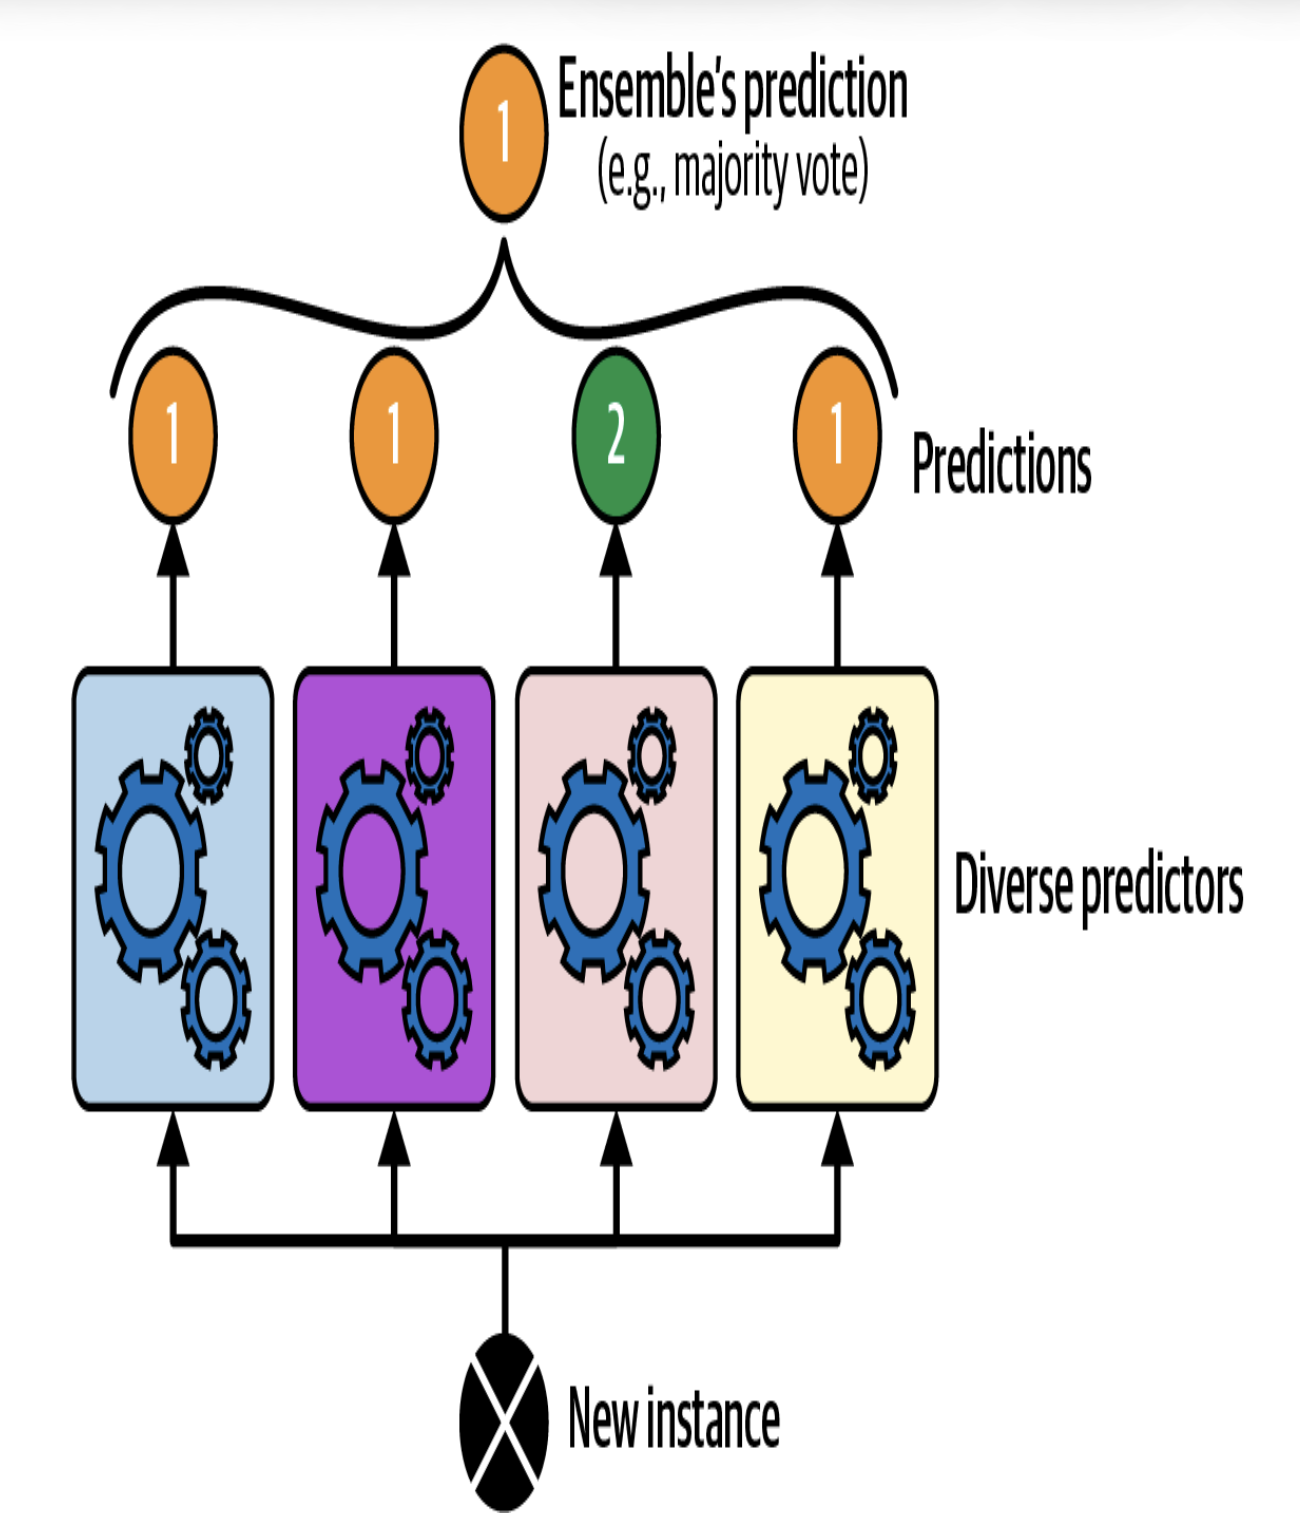

`G.K`

* somewhat , this voting classifier `often` achieves a higher accuracy .

* In
fact, even if each classifier is a weak learner (meaning it does only slightly better than random guessing), the ensemble
can still be a strong learner (achieving high accuracy), provided there are a sufficient number of weak learners in the
ensemble and they are sufficiently diverse (i.e., if they focus on different aspects of the data and make different kinds of
errors).


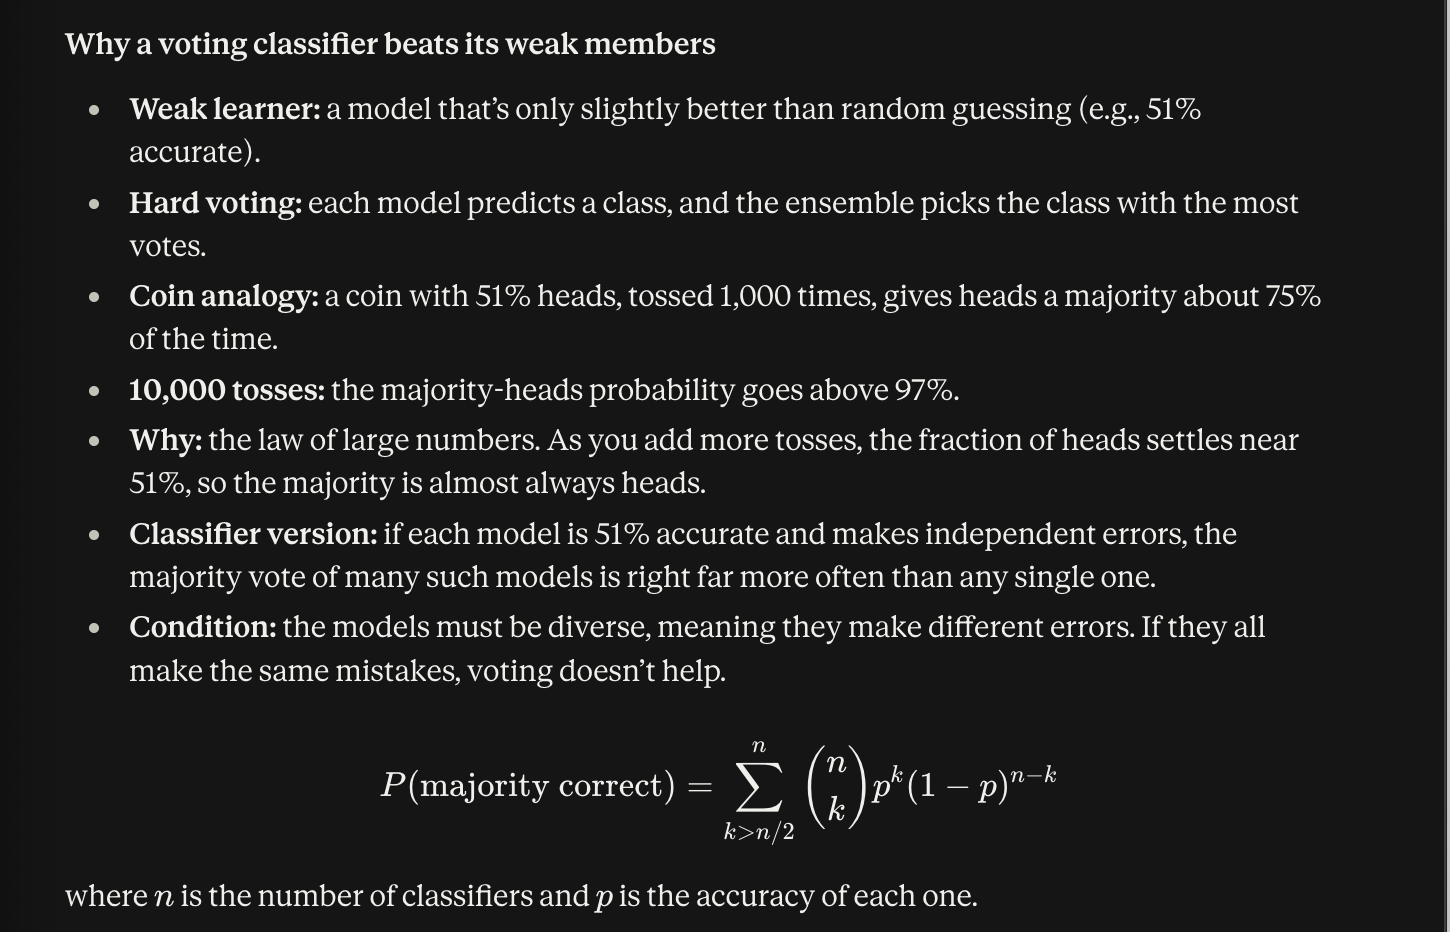

`TIP`

* Ensemble methods work best when the predictors are as independent from one another as possible.

* One way to get
diverse classifiers is to train them using very different algorithms.

1. This increases the chance that they will make very
different types of errors, improving the ensemble’s accuracy.

2. We can also try changing the model hyperparameters to get the diverse models, or train the models on different subsets of data .

`Working`

* We'll use Scikit-Learn  `VotingClassifier` class  .

* Just give it a list of name/predictor pairs, and
use it like a normal classifier.

* We'll use the moonds dataset.

* We will load and split the moons
dataset into a training set and a test set,

* Then we’ll create and train a voting classifier composed of three diverse
classifiers.

In [2]:
# Let's code it out
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X , y = make_moons(n_samples = 500 , noise = 0.30 , random_state = 42)
X_train , X_test , y_train , y_test = train_test_split(X,y, random_state = 42)

In [3]:
X_train[:3].round(2) , y_train[:3].round(2)

(array([[ 1.54,  0.19],
        [ 0.39,  0.32],
        [-0.92,  1.31]]),
 array([1, 0, 0]))

In [4]:
voting_clf = VotingClassifier(
    estimators = [
        ('lr' , LogisticRegression(random_state = 42)),
        ('rf' , RandomForestClassifier(random_state = 42)),
        ('svc' , SVC(random_state = 42))
    ]
)
voting_clf.fit(X_train , y_train)

VotingClassifier(estimators=[('lr', LogisticRegression(random_state=42)),
                             ('rf', RandomForestClassifier(random_state=42)),
                             ('svc', SVC(random_state=42))])

NOTE

* When you `fit` a `VotingClassifier`, it `clones` every `estimator` and fits the clones.


* The original estimators are available via the `estimators` attribute,

* while the fitted clones are available via the `estimators_`
attribute.

* If you prefer a dict rather than a list, you can use `named_estimators` or `named_estimators_.`

In [5]:
# Let's code it out
voting_clf.estimators

[('lr', LogisticRegression(random_state=42)),
 ('rf', RandomForestClassifier(random_state=42)),
 ('svc', SVC(random_state=42))]

In [6]:
# the fitted clones of the all the estimators
voting_clf.estimators_

[LogisticRegression(random_state=42),
 RandomForestClassifier(random_state=42),
 SVC(random_state=42)]

In [7]:
# Testing for dict  , for clones  ,
# similarly we can use named_estimators for no clone ones.

voting_clf.named_estimators_

{'lr': LogisticRegression(random_state=42),
 'rf': RandomForestClassifier(random_state=42),
 'svc': SVC(random_state=42)}

`.items():` a standard Python dictionary method that returns (key, value) pairs. Fixed.

In [8]:
# Lets look each fitted classifier's acc on the test set

for name , clf in voting_clf.named_estimators_.items():
  print(name, "=" , clf.score(X_test , y_test))


lr = 0.864
rf = 0.896
svc = 0.896


### 1.1 Hard voting

`Hard voting:` each model predicts a class label, and the final prediction is the majority label.

* Example: three models predict [1, 1, 0], so the ensemble predicts 1.
Ignores how confident each model is.


`The voting classifier’s predict() method, it performs hard voting .`

For example :-

* The voting classifier predicts class 1 for the first instance of the test set , because two of three classifier predict that class.

In [9]:
# X_test[:1] - means first row inside 2D array , shape(1,2)
voting_clf.predict(X_test[:1])

array([1])

In [10]:
[clf.predict(X_test[:1]) for clf in voting_clf.estimators_]

# all the predictions made on all the estimators for the first row


[array([1]), array([1]), array([0])]

In [11]:
# checking the performance of the voting classifier on the test set
voting_clf.score(X_test, y_test)


# reached the 91 % accurarcy

0.912

We can see this, the Voting classifier outperforms all the individuals classifiers.

### 1.2 Soft voting

In Soft voting: each model outputs class probabilities, the probabilities are averaged per class, and the class with the highest average wins.

* Example: model A gives [0.4, 0.6], B gives [0.3, 0.7], C gives [0.9, 0.1]. Averages are [0.53, 0.47], so the ensemble predicts class 0.

* Uses confidence, so a very sure model can outweigh two unsure ones.

* Requires every model to support predict_proba. SVC needs probability=True for this.

NOTE

1. If all classifier are able to estimate class probabiities , in short if all of them have predict_proba() method , then We should make Scikit-Learn to predict the class with the highest class probability ,

2. and getting the averaged over all the individual classifiers. This is called soft voting

ADVANTAGE
1. It often achieves higher performance than hard voting
why? , because it gives more weight to highly confident votes.


TO IMPLEMENT :-

* all we need to do is to se the voting classifier's voting hyperparameter to `soft` , and ensure that all classifiers can estimate class probbailities.

Disadvanage

1. This is not the case for the SVC class by default, so you need to set its
probability hyperparameter to True (this will make the SVC class use cross-validation to estimate class probabilities,
slowing down training, and it will add a predict
_proba() method)

In [12]:
# Let's code out for Soft voting
voting_clf.voting = "soft" # setting voting way to soft
voting_clf.named_estimators["svc"].probability = True
voting_clf.fit(X_train , y_train)


VotingClassifier(estimators=[('lr', LogisticRegression(random_state=42)),
                             ('rf', RandomForestClassifier(random_state=42)),
                             ('svc', SVC(probability=True, random_state=42))],
                 voting='soft')

In [13]:
voting_clf.score(X_test,y_test)
# reached the 92 percent accuracy

0.92

TIP

Soft voting works best when the estimated probabilities are well-calibrated. If they are not, then we can use `sklearn.calibration.CalibratedClassifierCV` to calibrate them

## 2.Bagging and Pasting

ONE way - To get a diverse set of classifiers is to use very different training algorithms.

Another way - use the same training algorithm for every predictor but train them on different random subsets of the training set.







---



BAGGING  (Bootstrap aggregating )

* When sampling is performed with replacement (different random subsets of the training set).



---



PASTING

*  When sampling is performed without replacement , it is called pasting .



---



In other words, both bagging and pasting allow training instances to be sampled several times across multiple predictors,
but only bagging allows training instances to be sampled several times for the same predictor.

This sampling and training
process is represented in figure 6.4

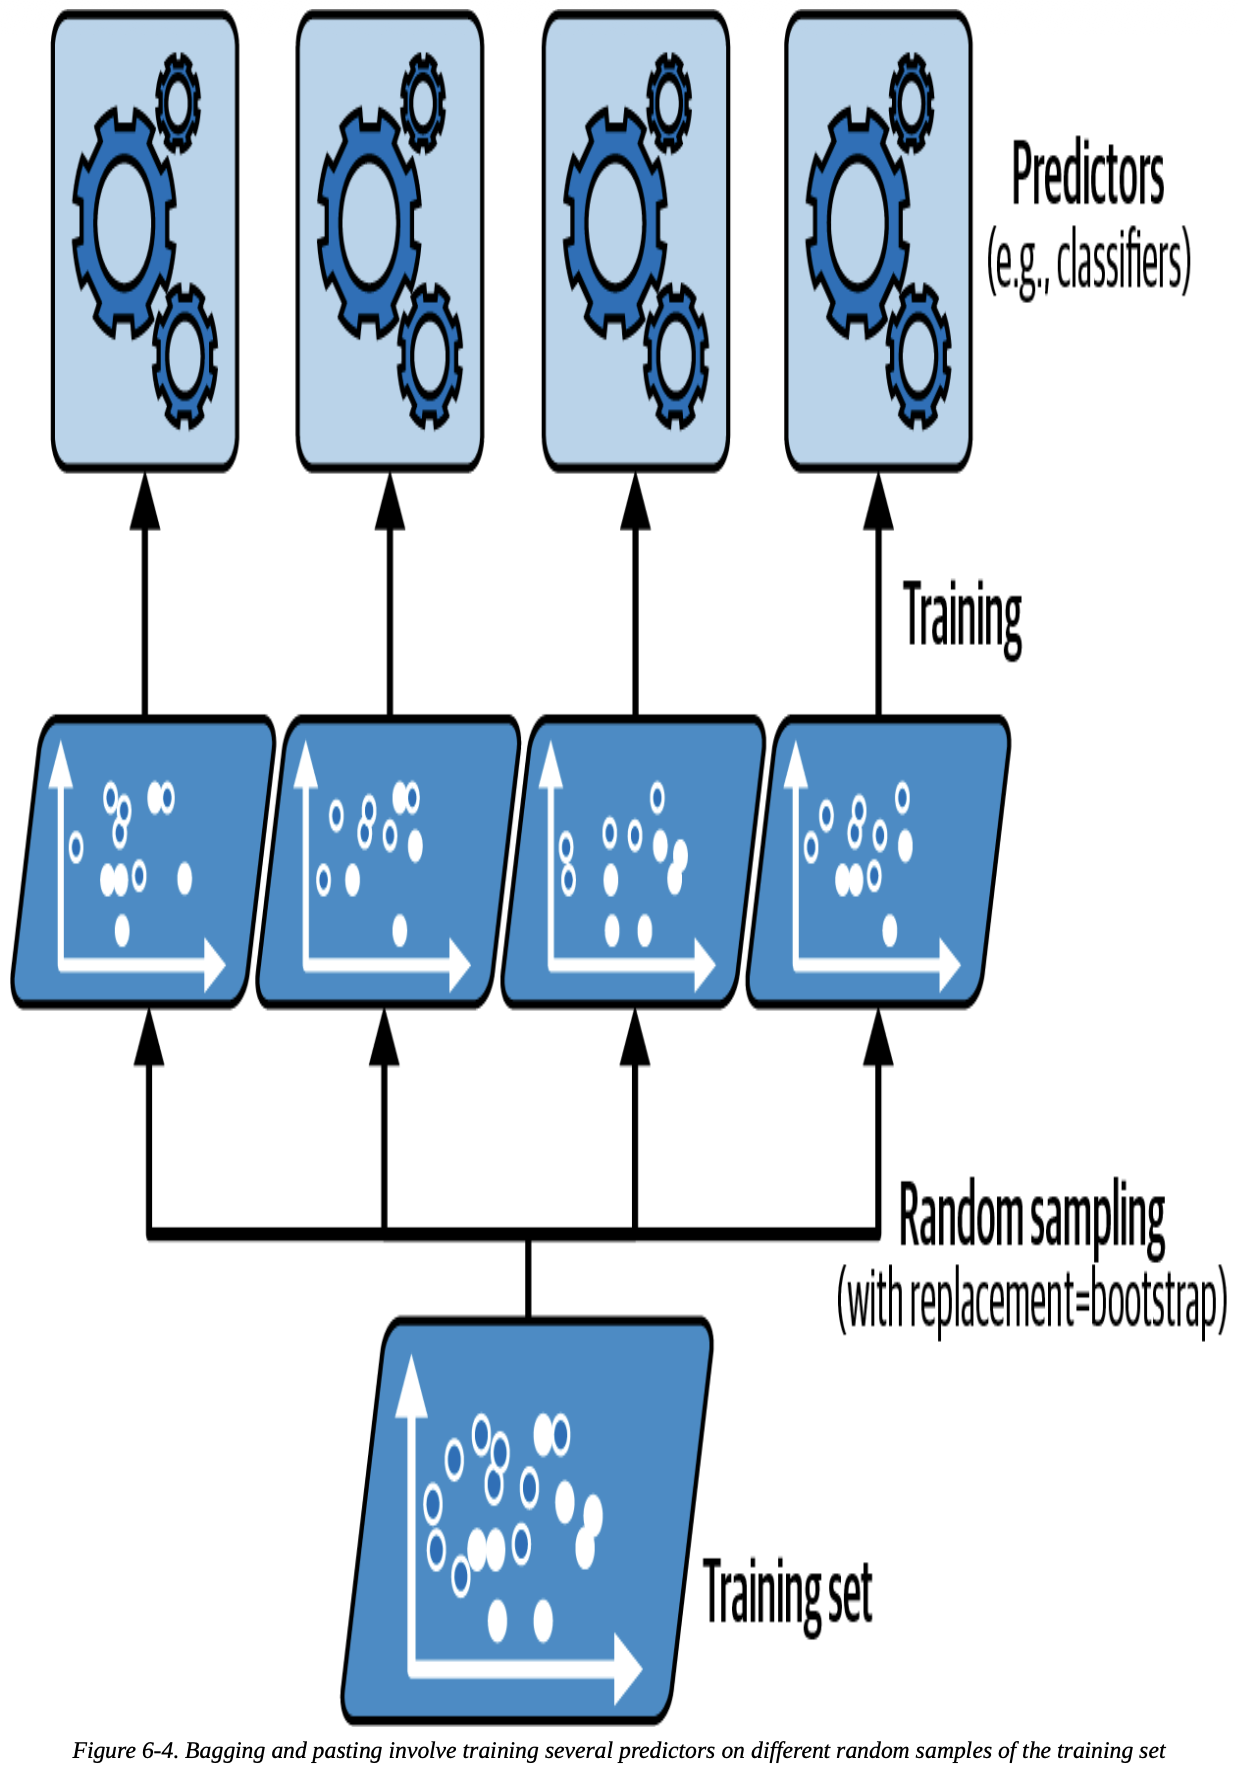



---



NOTE

Once all predictors are trained, the ensemble can make a prediction for a new instance by simply aggregating the
predictions of all predictors.

* For classification, the aggregation function is typically the `statistical mode` (i.e., the most
frequent prediction, just like with a hard voting classifier),

* for regression it’s usually just the `average.`


Each individual predictor has a higher bias than if it were trained on the original training set, `but aggregation reduces both bias and
variance.⁠`

`Standard deviation` measures how spread out a model’s predictions are around their average.

`TIP`

 Bagging use - when dataset is noisy or overfitting

 Pasting use - to avoid redundancy during training

### 2.1 Code Implementation bagging and pasting

`NOTE`

* predictors can all be trained in parallel, via different CPU cores or even different servers.
Similarly, predictions can be made in parallel

Code Setup :-

1. API avilable for both bagging and pasting: the BaggingClassifier class (or
BaggingRegressor for regression).

2. For bagging - trains an ensemble of 500 decision tree classifiers :  6 each is
trained on 100 training instances randomly sampled from the training set with replacement .

3. For pasting , set bootstrap = False.


4. n_jobs = no. of CPU cores used for training and predictions , if -1 then use all remaining.

In [14]:
# let's code it out
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bag_clf = BaggingClassifier(DecisionTreeClassifier(), n_estimators = 500 ,
                            max_samples = 100 , n_jobs = 1 , random_state = 42)
bag_clf.fit(X_train, y_train)
# max_samples = no. of instances
# n_estimators = amount of decision tree classifiers , so here 500 different dtc will be trained independently

BaggingClassifier(estimator=DecisionTreeClassifier(), max_samples=100,
                  n_estimators=500, n_jobs=1, random_state=42)

Bagging introduces a bit more diversity in the subsets that each predictor is trained on, so bagging ends up with a slightly
higher bias than pasting;

but more diversity means predictiors are less correlated.
thus ensemble's variance is reduced.

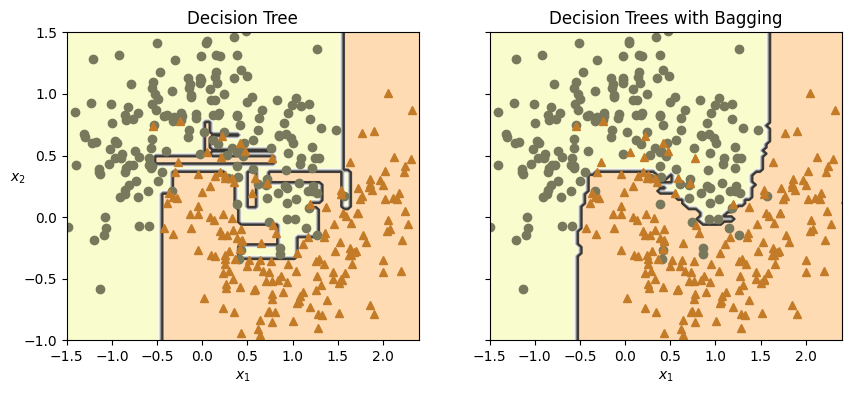

In [15]:
# extra code – this cell generates and saves Figure 7–5

def plot_decision_boundary(clf, X, y, alpha=1.0):
    axes=[-1.5, 2.4, -1, 1.5]
    x1, x2 = np.meshgrid(np.linspace(axes[0], axes[1], 100),
                         np.linspace(axes[2], axes[3], 100))
    X_new = np.c_[x1.ravel(), x2.ravel()]
    y_pred = clf.predict(X_new).reshape(x1.shape)

    plt.contourf(x1, x2, y_pred, alpha=0.3 * alpha, cmap='Wistia')
    plt.contour(x1, x2, y_pred, cmap="Greys", alpha=0.8 * alpha)
    colors = ["#78785c", "#c47b27"]
    markers = ("o", "^")
    for idx in (0, 1):
        plt.plot(X[:, 0][y == idx], X[:, 1][y == idx],
                 color=colors[idx], marker=markers[idx], linestyle="none")
    plt.axis(axes)
    plt.xlabel(r"$x_1$")
    plt.ylabel(r"$x_2$", rotation=0)

tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X_train, y_train)

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_decision_boundary(tree_clf, X_train, y_train)
plt.title("Decision Tree")
plt.sca(axes[1])
plot_decision_boundary(bag_clf, X_train, y_train)
plt.title("Decision Trees with Bagging")
plt.ylabel("")
plt.show()

## 3.Out-of-Bag Evaluation

OOB - the training instances that a particular tree did not see.




Disadvantage in bagging : -
* With bagging, some training instances may be sampled several times for any given predictor, while others may not be sampled at all.

Let's say that only 63 % of the training instances are sampled on average for each predictor ,

so the remaining % of the trainign instances that are not sampled are called `out-of-bag (OOB) instances`.

How the OOB evaluation works

1. Take one training instance, for example instance #7.

2. Find the trees that didn’t train on #7. With 500 trees, that’s usually around 185.

3. Ask only those trees to predict #7, then take a majority vote.

4. Compare that vote with the true label of #7.

5. Repeat for every training instance, then compute the accuracy.

In [16]:
# set oob_score=True when creating a BaggingClassifier to
# request an automatic OOBevaluation after training
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bag_clf = BaggingClassifier(DecisionTreeClassifier(), n_estimators = 500 ,
                            oob_score = True , n_jobs = 1 ,random_state = 42)

bag_clf.fit(X_train , y_train)
bag_clf.oob_score_ # we getting 89% evaluation score somehow

0.896

The evaluation score means

It's an performance measure , oob_score_ is the accuracy the model estimates for itself using the OOB trees, without needing a test set.

In [17]:
# According to above evaluation score ,
# we should be getting 89% acc on testing set too

# let's check it out
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
y_pred = bag_clf.predict(X_test)

accuracy_score(y_test , y_pred)
# we have to provide both real
# and predicted value  to check how good accuracy are

0.92

Got 92 percent acc on the test.

In [18]:
# Let's check the decision function for each training instance ,
# by using oob_decision_function_

from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bag_clf.oob_decision_function_[:3].round(2) # probas for the first 3 instances

array([[0.32, 0.68],
       [0.34, 0.66],
       [1.  , 0.  ]])

The flow, step by step which we covered

1. Training: BaggingClassifier trains 500 trees, each on a random sample of the training data. About 37% of training rows are left out of each tree’s sample.

2. OOB prediction: for each training row, take only the trees that left that row out and combine their votes into a prediction for that row.

3. OOB score: compare those OOB predictions with the true training labels. The accuracy is oob_score_ (0.896). No test data is used.

4. Test check: predict the test rows with the full ensemble, then compare with the true test labels using accuracy_score. The result is 0.92.

5. OOB decision function: this is step 2 again, but instead of keeping only the final label, it keeps the probabilities. For the first training row, the trees that never saw it give about 68% class 1 and 32% class 0. These are available as oob_decision_function_.

### 3.1 Random patches and Random Subspaces

* The BaggingClassifier class supports sampling the features as well .

Sampling is controlled by two hyperparameters:
* `max_features`
*  `bootstrap_features`

Working similar to max_samples and bootstrap but for feature sampling instead of instance sampling .



In simple words:

besides picking random rows (training instances) for each tree, BaggingClassifier can also pick random columns (features) for each tree.

* max_features: how many features each tree gets. For example, max_features=2 means each tree sees only 2 of the columns.

* bootstrap_features: whether those columns are picked with replacement, so the same column can be picked more than once. Default is False.

So each tree is trained on a random slice of the table: some of the rows and some of the columns. Each tree sees a different view of the data, which makes the trees more diverse, and that helps the ensemble.

For example, if your data has 10 features and you set max_features=5, each tree is trained on 5 randomly chosen features.

* It's used for dealing with high-dimensional inputes(e.g - images)

`Sampling both training instances and features is called the random patches method.`

Keeping all training instances (by setting bootstrap=False and max_samples=1.0) but sampling features (by
setting bootstrap_
features to True and/or max_features to a value smaller than 1.0) is called the `random
subspaces method.⁠`

## 4.Random Forest

`Random forest`
 is an ensemble of decision trees, generally trained via the bagging method (or
sometimes pasting),

Consists typically
*  max_samples , set to the size of the training set.

1. Instead of building a
BaggingClassifier and passing it a DecisionTreeClassifier, we can use the RandomForestClassifier
class, which is more convenient and optimized for decision trees .


2. similarly, there is a RandomForestRegressor class
for regression tasks .


In [19]:
# Code contains Rf classifier with 500 tree
# Limit to each tree with 16 max leaf nodes
# n_jobs = -1 using all cpus
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
rnd_clf = RandomForestClassifier(n_estimators = 500 , max_leaf_nodes = 16,
                                 n_jobs = -1 ,random_state = 42)

rnd_clf.fit(X_train , y_train)
y_pred_rf = rnd_clf.predict(X_test)
accuracy_score(y_test , y_pred_rf)

0.912

`NOTE`

*  `RandomForestClassifier` has all the hyperparameters of a DecisionTreeClassifier
(to control how trees are grown), plus all the hyperparameters of a BaggingClassifier to control the ensemble itself.

* Random forest = bagging + decision trees + random features at each split.

* Plain tree: checks all features to find the best split.
Random forest: checks only a random subset of features at each split.

* Default subset size: $$m = \sqrt{n}$$, where $n$ is the total number of features. For example, 16 features gives 4 per split.

* Effect: trees are more different from each other, so variance drops. Bias rises slightly, but the overall model is usually better.

NOTE

we can build almost the same model using a regular BaggingClassifier. You give it trees that each pick features with max_features="sqrt", so every split only looks at √n features, just like a random forest.

In [20]:
# So, the following BaggingClassifier (code) is equivalent
# to the previous RandomForestClassifier

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score

bag_clf2 = BaggingClassifier(DecisionTreeClassifier(max_features = "sqrt" , max_leaf_nodes = 16),
                            n_estimators = 500 , n_jobs = -1 ,random_state = 42)

bag_clf2.fit(X_train, y_train)
y_pred_bag = bag_clf2.predict(X_test)
accuracy_score(y_test, y_pred_bag)


0.912

### 4.1 Extra-Trees

Can make tress ever more random by using random thresholds for each feature rather than searching for the best possible thresholds(like regular decision trees do).



`To perform `
- simply set the splitter = "random" when creating a DecisionTreeClassifer.

A forest of such extremely random trees is called an `extremely randomized trees` ( or `extra-trees` for short ) ensemble.

ADV
-  Extra-trees classifiers are also much
faster to train than regular random forests.

We can create an extra-trees classifier using Scikit-Learn’s ExtraTreesClassifier class. Its API is identical to the
RandomForestClassifier class, except bootstrap defaults to False. Similarly, the ExtraTreesRegressor
class has the same API as the RandomForestRegressor class, except bootstrap defaults to False.

### 4.2 Feature Importance

Random forests Quality

- easy to measure the relative importance of each feature

To Measure Feature Importance
- Scikit-Learn measures a feature's importance by looking at how much the tree nodes that use that feature `reduce impurity`
on average, across all trees in the forest

Scikit-Learn computes this score automatically for each feature after training, then it scales the results so that the sum of
all importances is equal to 1.

- we can access the result using the `feature_importances_variable`

In [21]:
# Let's code it out
# Code contains , iris dataset ,
#  RandomForestClassifier ,and Outputs feature's importance

from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris

# loading the dataset
iris = load_iris(as_frame = True)

rf_clf = RandomForestClassifier(n_estimators = 500 , random_state = 42)
rf_clf.fit(iris.data , iris.target)

for score , name in zip(rf_clf.feature_importances_ , iris.data.columns):
  print(round(score, 2), name)


0.11 sepal length (cm)
0.02 sepal width (cm)
0.44 petal length (cm)
0.42 petal width (cm)


Code explains , how to read
```
for score , name in zip(rf_clf.feature_importances_ , iris.data.columns):
```
1. score - means  the score of importance of features ,

2. names - names of the features , that is why written the iris.data.columns for the names

3. in zip - means from the dataset


4. print(round(score, 2), name)
- means that give score and round it to 2 , with name of the featurs   



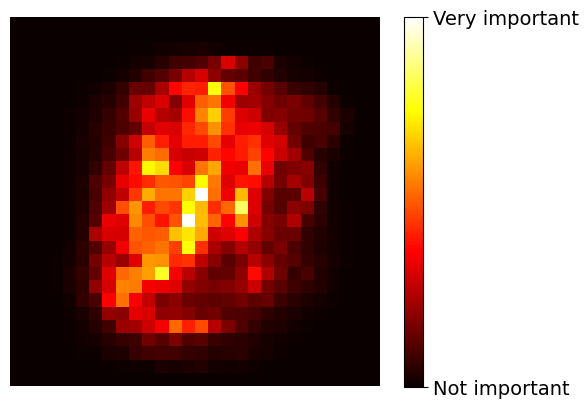

In [22]:
"""
Similarly, if we train a random forest classifier on the MNIST dataset
like we did on chapter 3 and plot each pixel’s importance,
"""


# extra code – this cell generates and saves Figure 7–6

from sklearn.datasets import fetch_openml

X_mnist, y_mnist = fetch_openml('mnist_784', return_X_y=True, as_frame=False,
                                parser='auto')

rnd_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rnd_clf.fit(X_mnist, y_mnist)

heatmap_image = rnd_clf.feature_importances_.reshape(28, 28)
plt.imshow(heatmap_image, cmap="hot")
cbar = plt.colorbar(ticks=[rnd_clf.feature_importances_.min(),
                           rnd_clf.feature_importances_.max()])
cbar.ax.set_yticklabels(['Not important', 'Very important'], fontsize=14)
plt.axis("off")
plt.show()

Conclusion

- Random forests are very handy to get a quick understanding of what features actually matter, in particular if i need to
perform feature selection

## 5.Boosting

Boosting / hypothesis boosting , refers to any ensemble method that can combine several weak learners into strong learner.

Idea is to train predictors squentially , each trying to correct it's predecessor .

There are many boosting methods available but most popular are `AdaBoost / adaptive boosting`

Bagging is like asking many people the same question separately and taking the majority. Boosting is like a team where each person looks at what the previous person got wrong and fixes i

### 5.1 AdaBoost / adaptative boosting

One way for a new predictor to correct its predecessor is to pay a bit more attention to the training instances that the
predecessor underfit. This results in new predictors focusing more and more on the hard cases. This is the technique used
by AdaBoost

For example, when training an AdaBoost classifier, the algorithm first trains a base classifier (such as a decision tree) and
uses it to make predictions on the training set. The algorithm then increases the relative weight of misclassified training
instances. Then it trains a second classifier, using the updated weights, and again makes predictions on the training set,
updates the instance weights, and so on

Drawback

Training can't be parallel , only sequential .

Once all predictors are trained, the ensemble makes predictions very much like bagging or pasting, except that predictors
have different weights depending on their overall accuracy on the weighted training set.

Closer look at the AdaBoost algorithm.

* Each instance weight w(i) is initially set to 1/m, so their sum is 1.

* A first predictor is trained, and its weighted error rate r1 is computed on the training set.

NOW

Whole Process

Step by Step



---



Equation

```
# Weighted error rate of the jth predictor
```




$$r_j = \sum_{\substack{i=1 \\ \hat{y}_j^{(i)} \neq y^{(i)}}}^{m} w^{(i)} \quad \text{where } \hat{y}_j^{(i)} \text{ is the } j^{th} \text{ predictor's prediction for the } i^{th} \text{ instance}$$

What the symbols mean

- $r_j$: weighted error rate of the $j$-th predictor

- $\sum$: add up the terms
$i=1$ to $m$: go through every training instance, where $m$ is the number of instances

- $\hat{y}_j^{(i)} \neq y^{(i)}$: only count instances the predictor got wrong

- $\hat{y}_j^{(i)}$: the $j$-th predictor’s prediction for instance $i$

- $y^{(i)}$: the true label of instance $i$

- $w^{(i)}$: the weight of instance $i$



---



Then the predictor's weight $α_j$ is then computed using :

Equation

```
Predictor weight
```






$$\alpha_j = \eta \log \frac{1 - r_j}{r_j}$$

- $\alpha_j$: the vote weight of the $j$-th predictor. Higher means a bigger say in the final prediction.

- $\eta$: the learning rate, a constant that scales all the weights. The default in Scikit-Learn is 1.

- $\log$: the natural logarithm.
$r_j$: the weighted error rate of the $j$-th predictor, from the previous equation.

- $\frac{1 - r_j}{r_j}$: the ratio of correct to incorrect weight. Low error makes this ratio large, and error near 0.5 makes it close to 1.



---



Next, the AdaBoost algorithm updates the instance weights, using , which boosts the weights of the misclassified instances and encourages the next predictor to pay more attention to them.

Equation

```
Weight update rule
```



$$\text{for } i = 1, 2, \dots, m$$

$$w^{(i)} \leftarrow \begin{cases} w^{(i)} & \text{if } \hat{y}^{(i)} = y^{(i)} \\ w^{(i)} \exp(\alpha_j) & \text{if } \hat{y}^{(i)} \neq y^{(i)} \end{cases}$$

Then all the instance weights are normalized to ensure that their sum is once again 1 (i.e., they are divided by $∑^m
_{i=1}$ w(i))



---



Finally, a new predictor is trained using the updated weights, and the whole process is repeated: the new predictor's
weight is computed, the instance weights are updated, then another predictor is trained, and so on. The algorithm stops
when the desired number of predictors is reached, or when a perfect predictor is found.

To make predictions, AdaBoost simply computes the predictions of all the predictors and weighs them using the predictor
weights αj. The predicted class is the one that receives the majority of weighted votes

Equation

```
AdaBoost Predictions
```



$$\hat{y}(\mathbf{x}) = \underset{k}{\operatorname{argmax}} \sum_{\substack{j=1 \\ \hat{y}_j(\mathbf{x}) = k}}^{N} \alpha_j \quad \text{where } N \text{ is the number of predictors}$$

- $\hat{y}(\mathbf{x})$: the final predicted class for input $\mathbf{x}$.

- $\mathbf{x}$: one input (one row of features).
$k$: a candidate class label, for example 0 or 1.

- $\underset{k}{\operatorname{argmax}}$: returns the class $k$ with the largest total. It gives the label, not the total itself.

- $\sum_{j=1}^{N}$: go through all $N$ predictors.
$\hat{y}_j(\mathbf{x}) = k$: the condition. Only predictors that vote for class $k$ are added.

- $\alpha_j$: the predictor’s vote weight

- $N$: the total number of predictors.



---



NOTE

Scikit-Learn uses a multiclass version of AdaBoost called SAMME (which stands for Stagewise Additive Modeling
using a Multiclass Exponential loss function). When there are just two classes, SAMME is equivalent to AdaBoost



---



The following code trains an AdaBoost classifier based on 30 decision stumps using Scikit-Learn’s
AdaBoostClassifier class (as you might expect, there is also an AdaBoostRegressor class). A decision stump is a
decision tree with max
_
depth=1—in other words, a tree composed of a single decision node plus two leaf nodes. This is
the default base estimator for the AdaBoostClassifier class:

In [23]:
# Let's code it out

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier

ada_clf = AdaBoostClassifier(
    DecisionTreeClassifier(max_depth = 1) , n_estimators = 30 ,
    learning_rate = 0.5 , random_state = 42 ,algorithm = "SAMME"
)
ada_clf.fit(X_train , y_train)



/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


AdaBoostClassifier(algorithm='SAMME',
                   estimator=DecisionTreeClassifier(max_depth=1),
                   learning_rate=0.5, n_estimators=30, random_state=42)

In [24]:
y_pred_ada = ada_clf.predict(X_test)
print("First 10 predictions : ", y_pred_ada[:10])
print("Test accuracy" , accuracy_score(y_test, y_pred_ada))


First 10 predictions :  [0 0 0 1 1 1 0 0 0 0]
Test accuracy 0.88


In [25]:
# alpha_j: vote weight of each stump
print("Predictor weights (alpha): " , ada_clf.estimator_weights_[:5].round(2))

# r_j : weighted error rate of each stump
print("predictor errors (r) : " , ada_clf.estimator_errors_[:5].round(2))


Predictor weights (alpha):  [0.75 0.54 0.42 0.49 0.32]
predictor errors (r) :  [0.18 0.25 0.3  0.27 0.35]


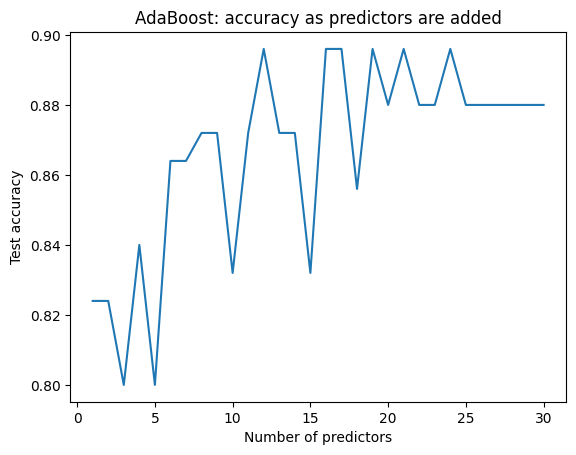

In [26]:
# extra code
import matplotlib.pyplot as plt

scores = list(ada_clf.staged_score(X_test, y_test))
plt.plot(range(1, len(scores) + 1), scores)
plt.xlabel("Number of predictors")
plt.ylabel("Test accuracy")
plt.title("AdaBoost: accuracy as predictors are added")
plt.show()

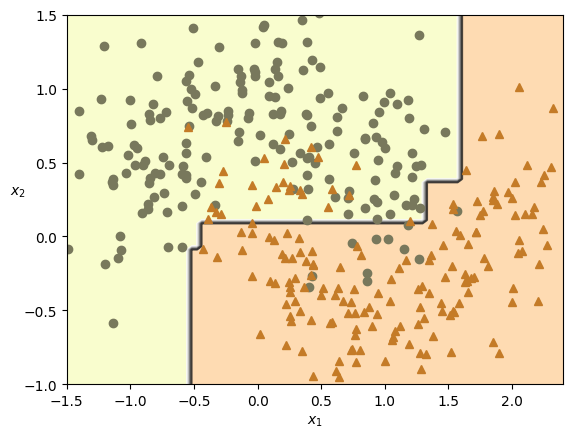

In [27]:
# extra code – in case you're curious to see what the decision boundary
#              looks like for the AdaBoost classifier
plot_decision_boundary(ada_clf, X_train, y_train)

If AdaBoost ensemble is overfitting the training set, we can try reducing the number of estimators or more
strongly regularizing the base estimator.

## 6.Gradient Boosting

Just like AdaBoost, gradient boosting works by
sequentially adding predictors to an ensemble, each one correcting its predecessor

However, instead of tweaking the
instance weights at every iteration like AdaBoost does, this method tries to fit the new predictor to the residual errors
made by the previous predictor.

Difference

both fix the previous predictor’s mistakes. They differ in how they do it.

AdaBoost: change the weights

- The target stays the true label $y$.
- Mistakes get larger instance weights $w^{(i)}$, so the next predictor pays more attention to them.
- The new predictor is trained on the same data, just weighted differently.

Gradient Boosting: change the target

- Each new predictor is trained on the residuals: $\text{residual} = y - \text{previous prediction}$.

- The residual is what the ensemble still gets wrong, so the new predictor learns to predict that leftover error directly.

- The final prediction is the sum of all predictors’ outputs.

- Example: true house price is $300k, and the first model predicts $250k.

Example - if true house price is 300k, and the first model predicts 250k.

- AdaBoost: the next model still aims for the 300 k dollars , tbut this house gets more weight
- Gradient Boosting: the next model aims for +50k, the residual.

Now a simple regression example, using decision trees as the base predictors; this is called gradient tree
boosting, or gradient boosted regression trees (GBRT).

In [28]:
# First, let’s generate a noisy quadratic dataset and
# fit a DecisionTreeRegressor to it

import numpy as np
from sklearn.tree import DecisionTreeRegressor

m = 100 # no. of instance
rng = np.random.default_rng(seed = 42)
X = rng.random((m,1)) - 0.5
noise = 0.05 * rng.standard_normal(m)

y = 3 * X[:, 0 ] ** 2 + noise #   y = 3x² + Gaussian noise

tree_reg1 = DecisionTreeRegressor(max_depth = 2, random_state = 42)
tree_reg1.fit(X,y)

DecisionTreeRegressor(max_depth=2, random_state=42)

In [29]:
# Next, we’ll train a second DecisionTreeRegressor on the residual
# errors made by the first predictor:
y2 = y - tree_reg1.predict(X)
print(y2[:2].round(2))


[ 0.15 -0.13]


In [30]:
tree_reg2 = DecisionTreeRegressor(max_depth = 2, random_state = 43)
tree_reg2.fit(X, y2)


DecisionTreeRegressor(max_depth=2, random_state=43)

In [31]:
# And then we’ll train a third regressor on the residual errors made by the second predictor:
y3 = y2 - tree_reg2.predict(X)
y3[:10].round(2)


array([ 0.17, -0.11, -0.06,  0.1 , -0.08,  0.  ,  0.08,  0.16,  0.03,
       -0.09])

In [32]:
tree_reg3 = DecisionTreeRegressor(max_depth =2 , random_state = 42)
tree_reg3.fit(X, y3)


DecisionTreeRegressor(max_depth=2, random_state=42)

Now we have an ensemble containing three trees. It can make predictions on a new instance simply by adding up the
predictions of all the trees:


In [33]:
X_new = np.array([[-0.4], [0.], [0.5]])
sum(tree.predict(X_new) for tree in (tree_reg1, tree_reg2, tree_reg3)).round(3)


array([0.574, 0.041, 0.669])

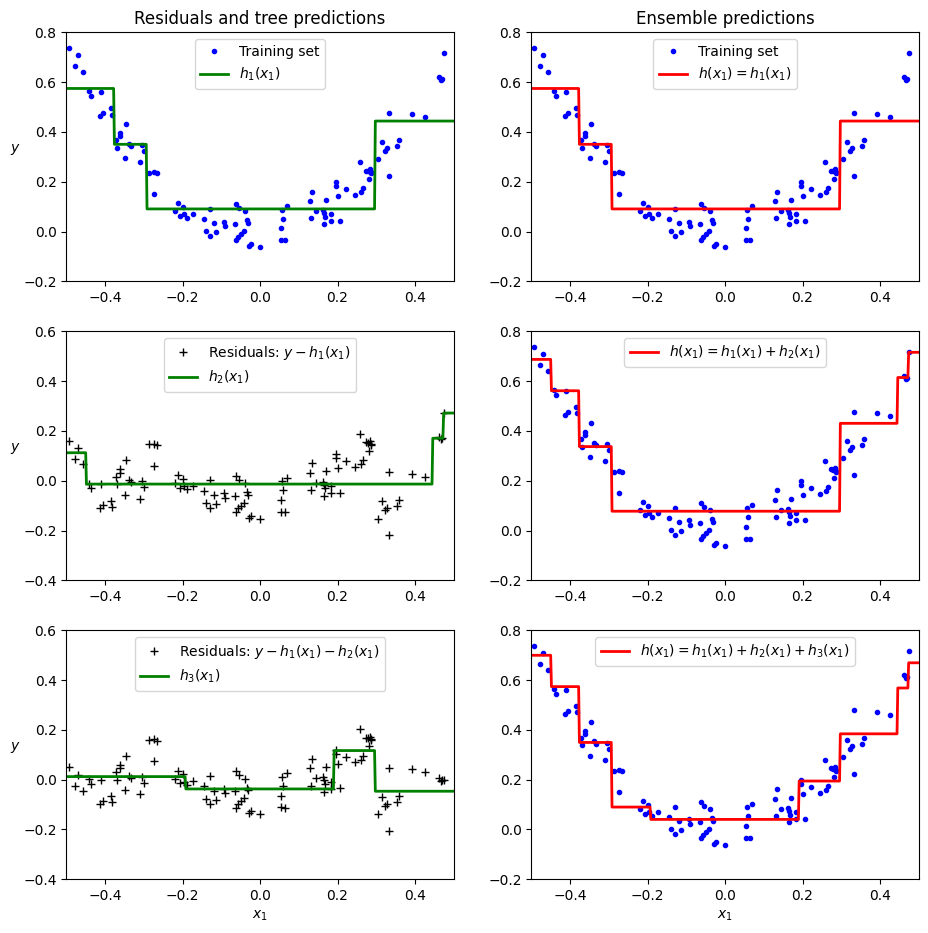

In [34]:
# extra code – this cell generates and saves Figure 7–9

def plot_predictions(regressors, X, y, axes, style,
                     label=None, data_style="b.", data_label=None):
    x1 = np.linspace(axes[0], axes[1], 500)
    y_pred = sum(regressor.predict(x1.reshape(-1, 1))
                 for regressor in regressors)
    plt.plot(X[:, 0], y, data_style, label=data_label)
    plt.plot(x1, y_pred, style, linewidth=2, label=label)
    if label or data_label:
        plt.legend(loc="upper center")
    plt.axis(axes)

plt.figure(figsize=(11, 11))

plt.subplot(3, 2, 1)
plot_predictions([tree_reg1], X, y, axes=[-0.5, 0.5, -0.2, 0.8], style="g-",
                 label="$h_1(x_1)$", data_label="Training set")
plt.ylabel("$y$  ", rotation=0)
plt.title("Residuals and tree predictions")

plt.subplot(3, 2, 2)
plot_predictions([tree_reg1], X, y, axes=[-0.5, 0.5, -0.2, 0.8], style="r-",
                 label="$h(x_1) = h_1(x_1)$", data_label="Training set")
plt.title("Ensemble predictions")

plt.subplot(3, 2, 3)
plot_predictions([tree_reg2], X, y2, axes=[-0.5, 0.5, -0.4, 0.6], style="g-",
                 label="$h_2(x_1)$", data_style="k+",
                 data_label="Residuals: $y - h_1(x_1)$")
plt.ylabel("$y$  ", rotation=0)

plt.subplot(3, 2, 4)
plot_predictions([tree_reg1, tree_reg2], X, y, axes=[-0.5, 0.5, -0.2, 0.8],
                  style="r-", label="$h(x_1) = h_1(x_1) + h_2(x_1)$")

plt.subplot(3, 2, 5)
plot_predictions([tree_reg3], X, y3, axes=[-0.5, 0.5, -0.4, 0.6], style="g-",
                 label="$h_3(x_1)$", data_style="k+",
                 data_label="Residuals: $y - h_1(x_1) - h_2(x_1)$")
plt.xlabel("$x_1$")
plt.ylabel("$y$  ", rotation=0)

plt.subplot(3, 2, 6)
plot_predictions([tree_reg1, tree_reg2, tree_reg3], X, y,
                 axes=[-0.5, 0.5, -0.2, 0.8], style="r-",
                 label="$h(x_1) = h_1(x_1) + h_2(x_1) + h_3(x_1)$")
plt.xlabel("$x_1$")
plt.show()

You can see that the ensemble’s predictions gradually get better as
trees are added to the ensemble.

You can use Scikit-Learn’s GradientBoostingRegressor class
to train GBRT ensembles more easily (there’s also a
GradientBoostingClassifier class for classification). Much like the RandomForestRegressor class, it has
hyperparameters to control the growth of decision trees (e.g., max
_
depth, min
_
samples
_
leaf), as well as
hyperparameters to control the ensemble training, such as the number of trees (n
_
estimators). The following code
creates the same ensemble as the previous one

In [35]:
# now let'se use the GradientBoostingRegressor

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error , r2_score

gbrt = GradientBoostingRegressor(max_depth = 2 , n_estimators = 3 ,
                                 learning_rate = 1.0  , random_state = 42)

gbrt.fit(X,y)


GradientBoostingRegressor(learning_rate=1.0, max_depth=2, n_estimators=3,
                          random_state=42)

In [36]:
# let's check the errors
y_gbrt = gbrt.predict(X)
print(f"MSE : {round(mean_squared_error(y_gbrt, y) ,4 )} ")
print(f"r2_score : {round(r2_score(y , y_gbrt), 4 )}")

MSE : 0.0037 
r2_score : 0.9115




---



Below code for more depth view

In [37]:
gbrt_best = GradientBoostingRegressor(
    max_depth = 2 , learning_rate = 0.05 , n_estimators = 500 ,
    random_state = 42 , n_iter_no_change = 10
)
gbrt_best.fit(X,y)

GradientBoostingRegressor(learning_rate=0.05, max_depth=2, n_estimators=500,
                          n_iter_no_change=10, random_state=42)

In [38]:
gbrt_best.n_estimators_

53

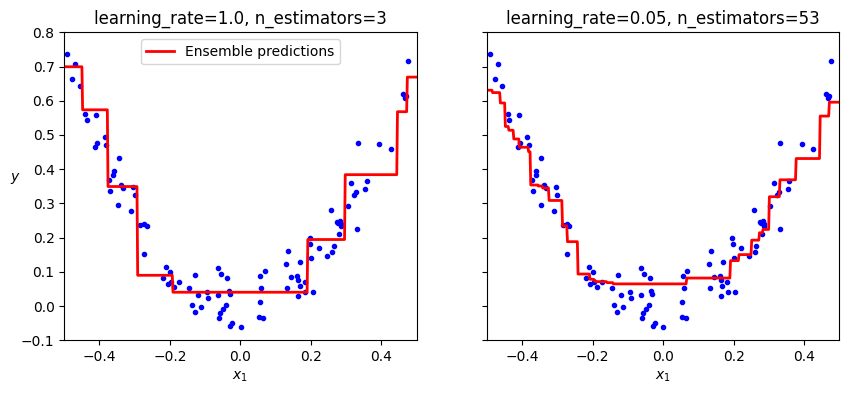

In [39]:
# extra code – this cell generates and saves Figure 7–10

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)

plt.sca(axes[0])
plot_predictions([gbrt], X, y, axes=[-0.5, 0.5, -0.1, 0.8], style="r-",
                 label="Ensemble predictions")
plt.title(f"learning_rate={gbrt.learning_rate}, "
          f"n_estimators={gbrt.n_estimators_}")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)

plt.sca(axes[1])
plot_predictions([gbrt_best], X, y, axes=[-0.5, 0.5, -0.1, 0.8], style="r-")
plt.title(f"learning_rate={gbrt_best.learning_rate}, "
          f"n_estimators={gbrt_best.n_estimators_}")
plt.xlabel("$x_1$")
plt.show()



---



The learning_rate hyperparameter scales the contribution of each tree . If you set it to a low value  such as 0.05, you
will need more trees in the ensemble to fit the training set, but the predictions will usually generalize better. This is a regularization technique called shrinkage.



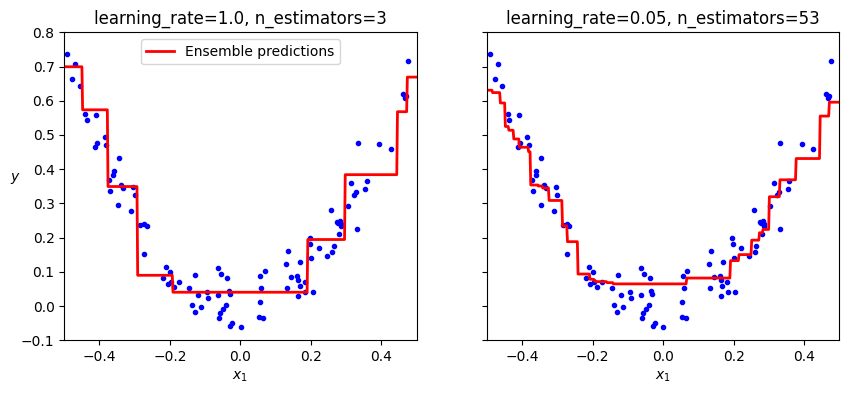

In [40]:
# extra code – this cell generates and saves Figure 7–10

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)

plt.sca(axes[0])
plot_predictions([gbrt], X, y, axes=[-0.5, 0.5, -0.1, 0.8], style="r-",
                 label="Ensemble predictions")
plt.title(f"learning_rate={gbrt.learning_rate}, "
          f"n_estimators={gbrt.n_estimators_}")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)

plt.sca(axes[1])
plot_predictions([gbrt_best], X, y, axes=[-0.5, 0.5, -0.1, 0.8], style="r-")
plt.title(f"learning_rate={gbrt_best.learning_rate}, "
          f"n_estimators={gbrt_best.n_estimators_}")
plt.xlabel("$x_1$")
plt.show()

shows two GBRT ensembles trained with different
hyperparameters: the one on the left does not have enough trees to fit the training set, while the one on the right has about
the right amount. If we added more trees, the GBRT would start to overfit the training set. As usual, you can use cross-
validation to find the optimal learning rate, using GridSearchCV or RandomizedSearchCV.

## 6.1 Histogram -Based Gradient Boosting

Scikit-Learn also provides another GBRT implementation, optimized for large datasets: histogram-based gradient
boosting (HGB).


Working

* binning the input features, replacing them with integers.

The number of bins is controlled by
the max
_
bins hyperparameter, which defaults to 255 and cannot be set any higher than this. Binning can greatly reduce
the number of possible thresholds that the training algorithm needs to evaluate. Moreover, working with integers makes it
possible to use faster and more memory-efficient data structures. And the way the bins are built removes the need for
sorting the features when training each tree.

In [41]:
# extra code – at least not in this chapter, it's presented in chapter 2

import pandas as pd
from sklearn.model_selection import train_test_split
import tarfile
import urllib.request

def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

housing = load_housing_data()

train_set, test_set = train_test_split(housing, test_size=0.2, random_state=42)
housing_labels = train_set["median_house_value"]
housing = train_set.drop("median_house_value", axis=1)

/tmp/ipykernel_5700/3054306454.py:15: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  housing_tarball.extractall(path="datasets")


In [42]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OrdinalEncoder

hgb_reg = make_pipeline(
    make_column_transformer((OrdinalEncoder(), ["ocean_proximity"]),
                            remainder="passthrough"),
    HistGradientBoostingRegressor(categorical_features=[0], random_state=42)
)
hgb_reg.fit(housing, housing_labels)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('ordinalencoder',
                                                  OrdinalEncoder(),
                                                  ['ocean_proximity'])])),
                ('histgradientboostingregressor',
                 HistGradientBoostingRegressor(categorical_features=[0],
                                               random_state=42))])

In [43]:
# extra code – evaluate the RMSE stats for the hgb_reg model

from sklearn.model_selection import cross_val_score

hgb_rmses = -cross_val_score(hgb_reg, housing, housing_labels,
                             scoring="neg_root_mean_squared_error", cv=10)
pd.Series(hgb_rmses).describe()

,0
count,10.000000
mean,47613.307194
std,1295.422509
min,44963.213061
25%,47001.233485
50%,48000.963564
75%,48488.093243
max,49176.368465


## 7.Extra , chapter 2 model code

Different way to create the model through GradientBoostingRegressor, Let's see it

In [44]:
# Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tarfile
import urllib.request

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error , r2_score


In [45]:
# Loading housing dataset of california

def load_housing_data():
  tarball_path = Path("datasets/housing.tgz")
  if not tarball_path.is_file():
    Path("datasets").mkdir(parents = True, exist_ok = True)
    url = "https://github.com/ageron/data/raw/main/housing.tgz"
    urllib.request.urlretrieve(url , tarball_path)

    with tarfile.open(tarball_path) as housing_tarball :
      housing_tarball.extractall(path = "datasets")

  return pd.read_csv(Path("datasets/housing/housing.csv"))

housing = load_housing_data()


In [46]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [47]:
# dataset splitting

train_set , test_set = train_test_split(housing, test_size = 0.2, random_state = 42)
y_train = train_set["median_house_value"]
y_test = test_set["median_house_value"]

X_train = train_set.drop("median_house_value" , axis = 1)
X_test = test_set.drop("median_house_value" , axis = 1)


In [48]:
len(X_train) , len(y_train) , len(X_test) , len(y_test)

(16512, 16512, 4128, 4128)

In [49]:
X_train[:2]

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
14196,-117.22,32.75,34.0,6001.0,1111.0,2654.0,1072.0,4.5878,NEAR OCEAN
8267,-117.03,32.69,10.0,901.0,163.0,698.0,167.0,4.6648,NEAR OCEAN


In [50]:
# fill missing total_bedrooms with the training median
medians = X_train.median(numeric_only = True)

X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)


In [51]:
# Turn the text column ocean_proximity into numbers (one-hot)

X_train = pd.get_dummies(X_train, columns=["ocean_proximity"], dtype=float)
X_test = pd.get_dummies(X_test, columns=["ocean_proximity"], dtype=float)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0.0)

In [52]:
print(X_train.columns.tolist())

['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


In [53]:
# Train the Gradient Boosting model

gbrt_housing = GradientBoostingRegressor(max_depth = 2 , n_estimators = 300 ,
                                         learning_rate = 0.1 ,random_state = 42)

gbrt_housing.fit(X_train , y_train)


GradientBoostingRegressor(max_depth=2, n_estimators=300, random_state=42)

In [54]:
# evaluate on the test set
from sklearn.metrics import root_mean_squared_error

y_pred_housing = gbrt_housing.predict(X_test)

print(f"RMSE : {round(root_mean_squared_error(y_test, y_pred_housing), 3 )}")

print(f"R2 : {round(r2_score(y_test, y_pred_housing) ,4)} ")


RMSE : 55232.184
R2 : 0.7799 


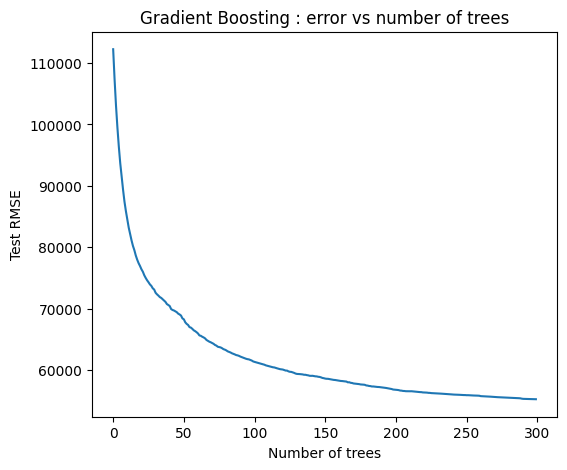

In [55]:
# Visualizing How the error drops as trees are added

val_errors = [root_mean_squared_error(y_test, p)for p in gbrt_housing.staged_predict(X_test)]

plt.figure(figsize = (6,5))
plt.plot(val_errors)
plt.xlabel("Number of trees")
plt.ylabel("Test RMSE")
plt.title("Gradient Boosting : error vs number of trees")
plt.show()

Notes

- Split first: the test set is separated before any preparation, so no information leaks into training.

- Median fill: total_bedrooms has missing values. The median comes from the training set only and is applied to both sets.

- One-hot encoding: ocean_proximity is text, so each category becomes a 0/1 column. reindex makes the test columns match the training columns.

- RMSE: the square root of MSE, in dollars, so it’s easier to read than MSE.
staged_predict: returns the prediction after 1, 2, 3, … trees. The plot shows the error going down, then flattening as more trees are added.

- Tuning: n_estimators and learning_rate interact. A smaller learning rate usually needs more trees. You can check the best number of trees with np.argmin(val_errors) + 1.



---



## 8.Stacking

One more ensemble method , also known as stacked generalization.



So basically all predictors predicts a different value (3.1 , 2.7 and 2.9) on an instance and then the final predictor (called blender or meta learner) takes these predictons as inputs and makes the final predicton.(3.0)


```
Aggregating predictions using a blending predictor.
```



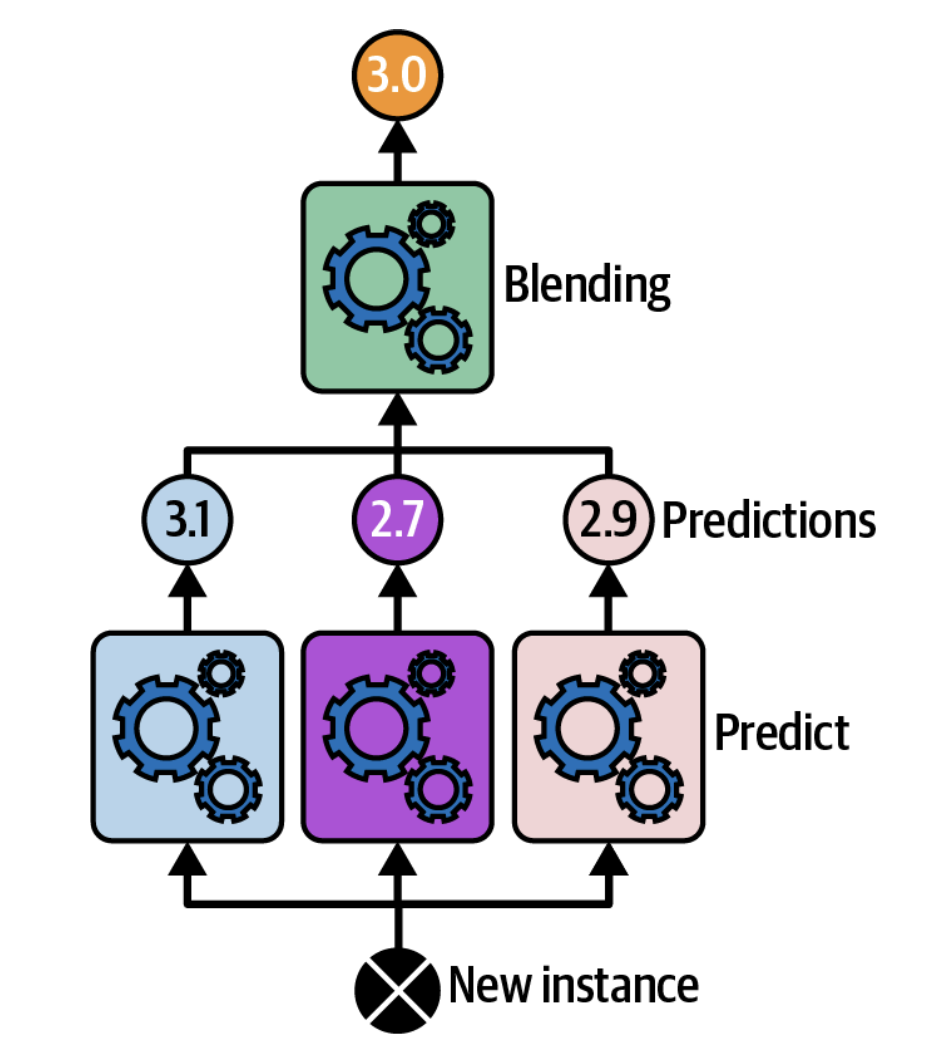

The difference is in how the predictions get combined.

- Bagging / Random forest: the same kind of model many times, each on different data. The combination is a fixed rule: majority vote or average. Every model counts equally.

- Boosting: models trained one after another, each fixing the previous one’s mistakes. The combination is a fixed weighted sum, where the weights come from each model’s accuracy.

- Stacking: different kinds of models, all trained on the same data. The combination is a learned model (the blender) that figures out how much to trust each base model, and when.

## 8.1 Train the blender

Steps -

- Need to first build the blending training set.
- Can use cross_val_predict() on every predictor in the ensemble  ,
- to get-out-of-sample predictions for each instance in the original training set.

 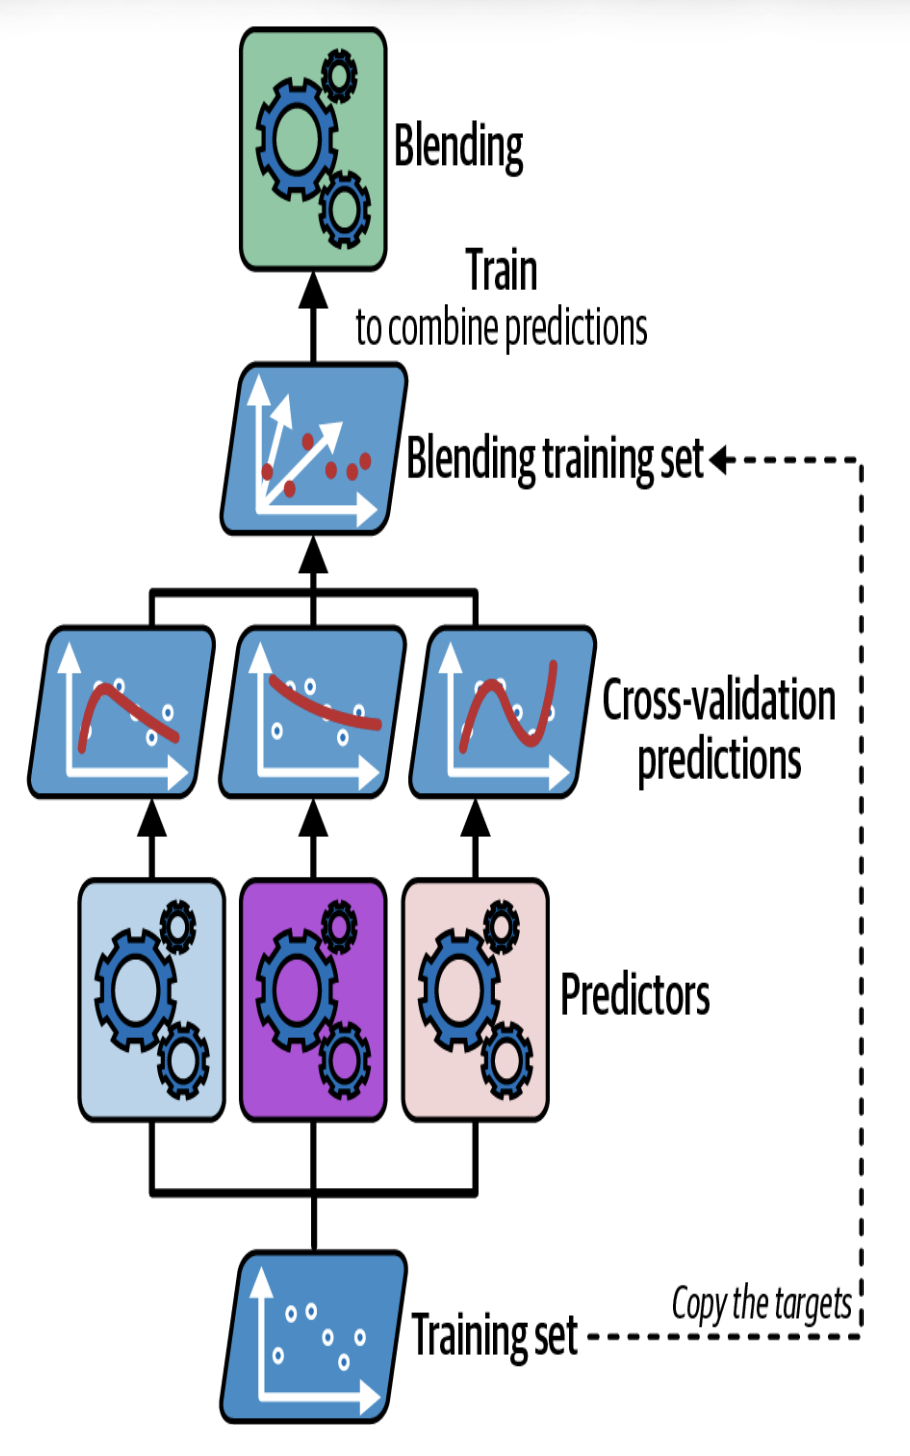

Step 1: Get out-of-fold predictions for the training set

Split the training set into 5 folds.
For each fold: train each base model on the other 4 folds, and predict the held-out fold.
Repeat until every fold has been held out once.
Result: one prediction per training row, each made by a model that never saw that row.
The 5 fold models are discarded after predicting. They are not used later.

Step 2: Build the blender’s training table

Each row is one training instance.
Each column is one base model’s predicted probability (or score) for that instance.